https://zivuch.github.io/nlp/nlp-day1-student-guide.html

In [2]:
# %pip install -q spacy nltk gensim wordcloud matplotlib seaborn scikit-learn

In [3]:
import nltk
from spacy.cli import download as spacy_download

for res in ["punkt", "punkt_tab", "wordnet", "omw-1.4", "stopwords",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng",
            "tagsets_json", "tagsets", "gutenberg"]:
    nltk.download(res, quiet=True)

try:
    import spacy
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy_download("en_core_web_sm")
    import spacy
    nlp = spacy.load("en_core_web_sm")

print("Language data ready.")

Language data ready.


In [4]:
import re, string
import numpy as np
import pandas as pd

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Setup complete!")

Setup complete!


In [5]:
REVIEWS = [
    "At McDonald's the food was ok and the service was bad.",
    "I wouldn't recommend this Japanese restaurant to anyone.",
    "I loved this restaurant when I traveled to Thailand last summer.",
    "The menu at Loving Hut has a wide variety of vegan options.",
    "The staff was friendly and helpful at Google's employee cafeteria.",
    "The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.",
    "I had a terrible experience at Pizza Hut. The pizza was burnt and the service was slow.",
    "The sushi at Sushi Express is always fresh and the prices are reasonable.",
    "The steakhouse on Main Street has a cozy atmosphere and excellent steaks.",
    "The dessert selection at Sweet Treats is amazing and the prices are fair.",
]

QUERY = "fresh sushi, reasonable prices"

print(f"{len(REVIEWS)} reviews loaded")
print(f"Query: '{QUERY}'")

10 reviews loaded
Query: 'fresh sushi, reasonable prices'


In [6]:
text = REVIEWS[7]
print(word_tokenize(text))

print()
print("Why not just split on spaces?")
print("  .split()      :", REVIEWS[1].split())
print("  word_tokenize :", word_tokenize(REVIEWS[1]))

['The', 'sushi', 'at', 'Sushi', 'Express', 'is', 'always', 'fresh', 'and', 'the', 'prices', 'are', 'reasonable', '.']

Why not just split on spaces?
  .split()      : ['I', "wouldn't", 'recommend', 'this', 'Japanese', 'restaurant', 'to', 'anyone.']
  word_tokenize : ['I', 'would', "n't", 'recommend', 'this', 'Japanese', 'restaurant', 'to', 'anyone', '.']


In [7]:
paragraph = REVIEWS[6]
sentences = sent_tokenize(paragraph)

print(f"Review [6]: '{paragraph}'\n")
print(f"word_tokenize gives {len(word_tokenize(paragraph))} pieces (words)")
print(f"sent_tokenize gives {len(sentences)} pieces (sentences):")
for i, sent in enumerate(sentences, 1):
    print(f"  {i}. {sent}")

Review [6]: 'I had a terrible experience at Pizza Hut. The pizza was burnt and the service was slow.'

word_tokenize gives 19 pieces (words)
sent_tokenize gives 2 pieces (sentences):
  1. I had a terrible experience at Pizza Hut.
  2. The pizza was burnt and the service was slow.


In [10]:
stop_words = set(stopwords.words('english'))
print(f"English stopwords: {len(stop_words)}")
print(sorted(stop_words)[:15])

tokens = word_tokenize(REVIEWS[8].lower())
kept = [t for t in tokens if t not in stop_words]
print()
print("before:", tokens)
print("after :", kept)

English stopwords: 198
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't"]

before: ['the', 'steakhouse', 'on', 'main', 'street', 'has', 'a', 'cozy', 'atmosphere', 'and', 'excellent', 'steaks', '.']
after : ['steakhouse', 'main', 'street', 'cozy', 'atmosphere', 'excellent', 'steaks', '.']


In [11]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

words = ["prices", "dishes", "steaks", "options",
         "traveled", "loved", "friendly", "amazing"]

print(f"{'word':<12}{'stemmed':<12}{'lemma':<12}{'lemma as verb'}")
print("-" * 52)
for w in words:
    print(f"{w:<12}{stemmer.stem(w):<12}"
          f"{lemmatizer.lemmatize(w):<12}{lemmatizer.lemmatize(w, pos='v')}")

word        stemmed     lemma       lemma as verb
----------------------------------------------------
prices      price       price       price
dishes      dish        dish        dish
steaks      steak       steak       steaks
options     option      option      options
traveled    travel      traveled    travel
loved       love        loved       love
friendly    friendli    friendly    friendly
amazing     amaz        amazing     amaze


In [12]:
def preprocess_text(text):
    text = text.lower()                                             # 1 lowercase
    tokens = word_tokenize(text)                                    # 2 split into words
    tokens = [t for t in tokens if t not in string.punctuation]     # 3 drop punctuation
    tokens = [t for t in tokens if t not in stop_words]             # 4 drop stopwords
    tokens = [lemmatizer.lemmatize(t) for t in tokens]              # 5 back to root form
    return ' '.join(tokens)

clean_reviews = [preprocess_text(r) for r in REVIEWS]

for i, (raw, clean) in enumerate(zip(REVIEWS, clean_reviews)):
    print(f"[{i}] {clean}")

[0] mcdonald 's food ok service bad
[1] would n't recommend japanese restaurant anyone
[2] loved restaurant traveled thailand last summer
[3] menu loving hut wide variety vegan option
[4] staff friendly helpful google 's employee cafeteria
[5] ambiance bella italia amazing pasta dish delicious
[6] terrible experience pizza hut pizza burnt service slow
[7] sushi sushi express always fresh price reasonable
[8] steakhouse main street cozy atmosphere excellent steak
[9] dessert selection sweet treat amazing price fair


In [13]:
mini_docs = ["sushi fresh prices reasonable",
             "pizza burnt service slow",
             "sushi pizza service amazing"]

cv = CountVectorizer()
bow = cv.fit_transform(mini_docs)

print("Vocabulary:", cv.get_feature_names_out())
print()
print(pd.DataFrame(bow.toarray(),
                   columns=cv.get_feature_names_out(),
                   index=["Doc1", "Doc2", "Doc3"]))

Vocabulary: ['amazing' 'burnt' 'fresh' 'pizza' 'prices' 'reasonable' 'service' 'slow'
 'sushi']

      amazing  burnt  fresh  pizza  prices  reasonable  service  slow  sushi
Doc1        0      0      1      0       1           1        0     0      1
Doc2        0      1      0      1       0           0        1     1      0
Doc3        1      0      0      1       0           0        1     0      1


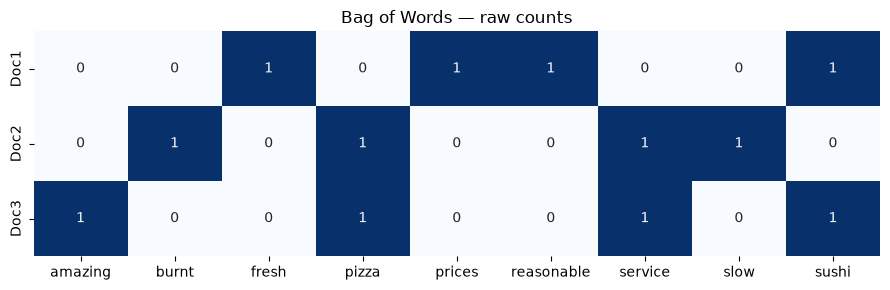

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 3))
sns.heatmap(pd.DataFrame(bow.toarray(),
                         columns=cv.get_feature_names_out(),
                         index=["Doc1", "Doc2", "Doc3"]),
            annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Bag of Words — raw counts")
plt.tight_layout(); plt.show()

In [15]:
tv = TfidfVectorizer()
tfidf_mini = tv.fit_transform(mini_docs)

print(pd.DataFrame(tfidf_mini.toarray().round(2),
                   columns=tv.get_feature_names_out(),
                   index=["Doc1", "Doc2", "Doc3"]))

      amazing  burnt  fresh  pizza  prices  reasonable  service  slow  sushi
Doc1      0.0   0.00   0.53   0.00    0.53        0.53     0.00  0.00   0.40
Doc2      0.0   0.56   0.00   0.43    0.00        0.00     0.43  0.56   0.00
Doc3      0.6   0.00   0.00   0.46    0.00        0.00     0.46  0.00   0.46


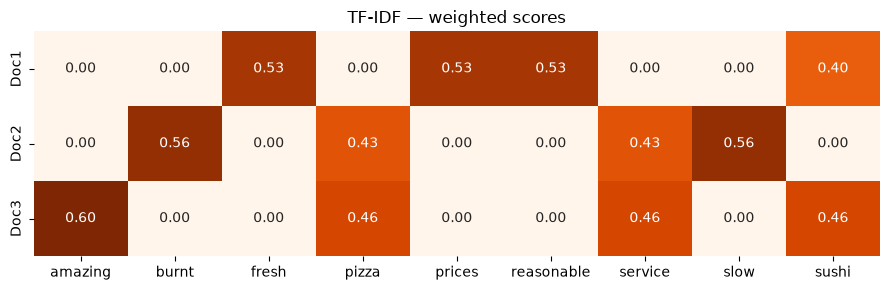

In [16]:
plt.figure(figsize=(9, 3))
sns.heatmap(pd.DataFrame(tfidf_mini.toarray(),
                         columns=tv.get_feature_names_out(),
                         index=["Doc1", "Doc2", "Doc3"]),
            annot=True, fmt='.2f', cmap='Oranges', cbar=False)
plt.title("TF-IDF — weighted scores")
plt.tight_layout(); plt.show()

In [17]:
tfidf = TfidfVectorizer()
doc_vectors = tfidf.fit_transform(clean_reviews)

clean_query  = preprocess_text(QUERY)          # the SAME cleaning as the reviews
query_vector = tfidf.transform([clean_query])  # transform, NOT fit_transform

scores = cosine_similarity(query_vector, doc_vectors)[0]

print(f"QUERY:   '{QUERY}'")
print(f"CLEANED: '{clean_query}'\n")
for i in np.argsort(scores)[::-1][:5]:
    print(f"{scores[i]:.3f}  [{i}] {REVIEWS[i]}")

QUERY:   'fresh sushi, reasonable prices'
CLEANED: 'fresh sushi reasonable price'

0.829  [7] The sushi at Sushi Express is always fresh and the prices are reasonable.
0.148  [9] The dessert selection at Sweet Treats is amazing and the prices are fair.
0.000  [8] The steakhouse on Main Street has a cozy atmosphere and excellent steaks.
0.000  [6] I had a terrible experience at Pizza Hut. The pizza was burnt and the service was slow.
0.000  [5] The ambiance at Bella Italia is amazing, and the pasta dishes are delicious.


In [20]:
PARAPHRASE = "somewhere with good raw fish that is not expensive"

clean_p = preprocess_text(PARAPHRASE)
p_scores = cosine_similarity(tfidf.transform([clean_p]), doc_vectors)[0]

print(f"PARAPHRASE: '{PARAPHRASE}'")
print(f"cleaned:    '{clean_p}'\n")
for i in np.argsort(p_scores)[::-1][:10]:
    print(f"{p_scores[i]:.3f}  [{i}] {REVIEWS[i][:60]}")

print(f"\nBest score: {p_scores.max():.3f}")

PARAPHRASE: 'somewhere with good raw fish that is not expensive'
cleaned:    'somewhere good raw fish expensive'

0.000  [9] The dessert selection at Sweet Treats is amazing and the pri
0.000  [8] The steakhouse on Main Street has a cozy atmosphere and exce
0.000  [7] The sushi at Sushi Express is always fresh and the prices ar
0.000  [6] I had a terrible experience at Pizza Hut. The pizza was burn
0.000  [5] The ambiance at Bella Italia is amazing, and the pasta dishe
0.000  [4] The staff was friendly and helpful at Google's employee cafe
0.000  [3] The menu at Loving Hut has a wide variety of vegan options.
0.000  [2] I loved this restaurant when I traveled to Thailand last sum
0.000  [1] I wouldn't recommend this Japanese restaurant to anyone.
0.000  [0] At McDonald's the food was ok and the service was bad.

Best score: 0.000


In [21]:
for q in ["Loving Hut", "Pizza Hut"]:
    clean_q = preprocess_text(q)
    q_scores = cosine_similarity(tfidf.transform([clean_q]), doc_vectors)[0]

    print(f"QUERY: '{q}'   cleaned: '{clean_q}'")
    for i in np.argsort(q_scores)[::-1][:3]:
        print(f"  {q_scores[i]:.3f}  [{i}] {REVIEWS[i][:60]}")
    print()

QUERY: 'Loving Hut'   cleaned: 'loving hut'
  0.506  [3] The menu at Loving Hut has a wide variety of vegan options.
  0.179  [6] I had a terrible experience at Pizza Hut. The pizza was burn
  0.000  [8] The steakhouse on Main Street has a cozy atmosphere and exce

QUERY: 'Pizza Hut'   cleaned: 'pizza hut'
  0.675  [6] I had a terrible experience at Pizza Hut. The pizza was burn
  0.212  [3] The menu at Loving Hut has a wide variety of vegan options.
  0.000  [8] The steakhouse on Main Street has a cozy atmosphere and exce



In [22]:
text = REVIEWS[7]
tokens = word_tokenize(text)        # no lowercasing this time
pos_tags = pos_tag(tokens)

print(f"Review [7]: '{text}'\n")
for word, tag in pos_tags:
    print(f"  {word:10} → {tag}")

Review [7]: 'The sushi at Sushi Express is always fresh and the prices are reasonable.'

  The        → DT
  sushi      → NN
  at         → IN
  Sushi      → NNP
  Express    → NNP
  is         → VBZ
  always     → RB
  fresh      → JJ
  and        → CC
  the        → DT
  prices     → NNS
  are        → VBP
  reasonable → JJ
  .          → .


In [23]:
import nltk.help

for tag in ["NNP", "JJ"]:
    nltk.help.upenn_tagset(tag)

NNP: noun, proper, singular
    Motown Venneboerger Czestochwa Ranzer Conchita Trumplane Christos
    Oceanside Escobar Kreisler Sawyer Cougar Yvette Ervin ODI Darryl CTCA
    Shannon A.K.C. Meltex Liverpool ...
JJ: adjective or numeral, ordinal
    third ill-mannered pre-war regrettable oiled calamitous first separable
    ectoplasmic battery-powered participatory fourth still-to-be-named
    multilingual multi-disciplinary ...


In [24]:
def find_names(text):
    return [(e.text, e.label_) for e in nlp(text).ents]

print("RAW    :", REVIEWS[7])
print("  found:", find_names(REVIEWS[7]))
print()
print("CLEANED:", clean_reviews[7])
print("  found:", find_names(clean_reviews[7]))

RAW    : The sushi at Sushi Express is always fresh and the prices are reasonable.
  found: [('Sushi Express', 'ORG')]

CLEANED: sushi sushi express always fresh price reasonable
  found: []


In [25]:
entities = [find_names(review) for review in REVIEWS]

for i, ents in enumerate(entities):
    print(f"[{i}] {REVIEWS[i][:52]}")
    for text, label in ents:
        print(f"      {text:15} {label:8} {spacy.explain(label)}")

[0] At McDonald's the food was ok and the service was ba
      McDonald        ORG      Companies, agencies, institutions, etc.
[1] I wouldn't recommend this Japanese restaurant to any
      Japanese        NORP     Nationalities or religious or political groups
[2] I loved this restaurant when I traveled to Thailand 
      Thailand        GPE      Countries, cities, states
      last summer     DATE     Absolute or relative dates or periods
[3] The menu at Loving Hut has a wide variety of vegan o
      Loving Hut      ORG      Companies, agencies, institutions, etc.
[4] The staff was friendly and helpful at Google's emplo
      Google          ORG      Companies, agencies, institutions, etc.
[5] The ambiance at Bella Italia is amazing, and the pas
      Bella Italia    ORG      Companies, agencies, institutions, etc.
[6] I had a terrible experience at Pizza Hut. The pizza 
      Pizza Hut       ORG      Companies, agencies, institutions, etc.
[7] The sushi at Sushi Express is always f

In [26]:
organizations = sorted({text for ents in entities
                        for text, label in ents if label == "ORG"})
print("Restaurants we can filter on:")
print(" ", organizations)

best = int(np.argsort(scores)[::-1][0])
print(f"\nTop TF-IDF hit: [{best}] {REVIEWS[best]}")
print(f"Its entities:   {entities[best]}")

Restaurants we can filter on:
  ['Bella Italia', 'Google', 'Loving Hut', 'McDonald', 'Pizza Hut', 'Sushi Express']

Top TF-IDF hit: [7] The sushi at Sushi Express is always fresh and the prices are reasonable.
Its entities:   [('Sushi Express', 'ORG')]


In [27]:
from gensim.models import Word2Vec

tokenized_reviews = [review.split() for review in clean_reviews]

print("clean_reviews → tokenized_reviews:")
for i, tokens in enumerate(tokenized_reviews[:3]):
    print(f"  [{i}] {tokens}")

vocab = sorted({t for tokens in tokenized_reviews for t in tokens})
print(f"\nDistinct words in our corpus: {len(vocab)}")

clean_reviews → tokenized_reviews:
  [0] ['mcdonald', "'s", 'food', 'ok', 'service', 'bad']
  [1] ['would', "n't", 'recommend', 'japanese', 'restaurant', 'anyone']
  [2] ['loved', 'restaurant', 'traveled', 'thailand', 'last', 'summer']

Distinct words in our corpus: 60


In [28]:
w2v = Word2Vec(
    sentences=tokenized_reviews,
    vector_size=50,   # length of each word's list of numbers
    window=3,         # how many words either side count as "context"
    min_count=1,      # keep every word (normally 5+)
    sg=1,             # skip-gram
    epochs=100,
    seed=42, workers=1,
)

print(f"Vocabulary: {len(w2v.wv)} words, {w2v.wv.vector_size} numbers each\n")
print("First 8 numbers for 'sushi':")
print(w2v.wv['sushi'][:8].round(3))

print("\nWords Word2Vec thinks are closest to 'sushi':")
for w, score in w2v.wv.most_similar('sushi', topn=5):
    print(f"  {w:12} {score:.3f}")

Vocabulary: 60 words, 50 numbers each

First 8 numbers for 'sushi':
[ 0.01  -0.013 -0.005 -0.002  0.001 -0.018  0.    -0.012]

Words Word2Vec thinks are closest to 'sushi':
  dessert      0.366
  staff        0.295
  variety      0.291
  main         0.282
  loved        0.273


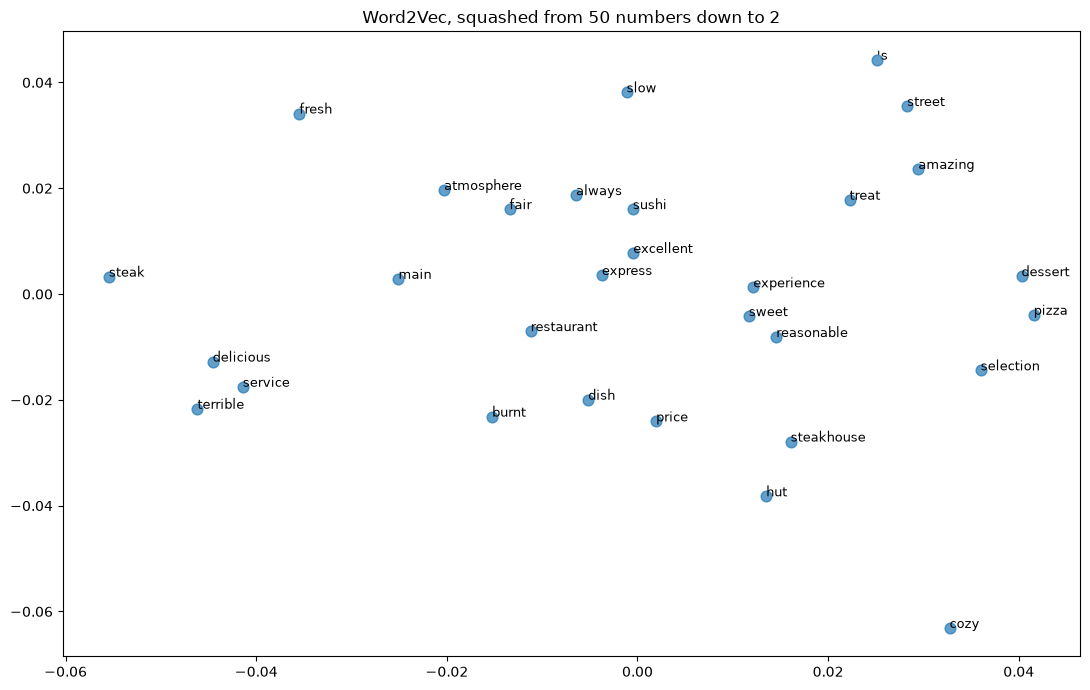

In [29]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

words  = list(w2v.wv.key_to_index)[:30]
vectors = np.array([w2v.wv[w] for w in words])
coords  = PCA(n_components=2).fit_transform(vectors)

plt.figure(figsize=(11, 7))
plt.scatter(coords[:, 0], coords[:, 1], s=60, alpha=.7)
for i, word in enumerate(words):
    plt.annotate(word, (coords[i, 0], coords[i, 1]), fontsize=9)
plt.title("Word2Vec, squashed from 50 numbers down to 2")
plt.tight_layout(); plt.show()